# 🔵1) downloads and imports

### 🟠1.1) download stable-diffusion-2-base

In [3]:
# if needed 
#!pip install --upgrade diffusers transformers accelerate scipy safetensors

In [4]:
import torch
from diffusers import StableDiffusionPipeline, EulerDiscreteScheduler

# model name and location
model_id = "sd2-community/stable-diffusion-2-base"

scheduler = EulerDiscreteScheduler.from_pretrained(model_id, subfolder="scheduler")

# defining the base pipeline
pipe = StableDiffusionPipeline.from_pretrained(
    model_id, 
    scheduler=scheduler, 
    torch_dtype=torch.float16 
)

# as in the other HW we have done, move it to cuda...
pipe = pipe.to("cuda")

# basic prompt to test
prompt = "A small dog, wearing sun glasses and mexican hat"

# running the prompt thru the pipe, and getting resaults
image = pipe(prompt).images[0]

#save and disply the image 
image.save("basic_stable_deffusion_check.png")
print("image saved as basic_stable_deffusion_check.png")

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [3]:
import torch
from diffusers import StableDiffusionPipeline, EulerDiscreteScheduler

# model name and location
model_id = "sd2-community/stable-diffusion-2-base"

scheduler = EulerDiscreteScheduler.from_pretrained(model_id, subfolder="scheduler")

# defining the base pipeline
pipe = StableDiffusionPipeline.from_pretrained(
    model_id, 
    scheduler=scheduler, 
    torch_dtype=torch.float16 
)

# as in the other HW we have done, move it to cuda...
pipe = pipe.to("cuda")

# basic prompt to test
prompt = "A small dog, wearing sun glasses and mexican hat"

# running the prompt thru the pipe, and getting resaults
image = pipe(prompt).images[0]

#save and disply the image 
image.save("basic_stable_deffusion_check.png")
print("image saved as basic_stable_deffusion_check.png")

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

image saved as basic_stable_deffusion_check.png


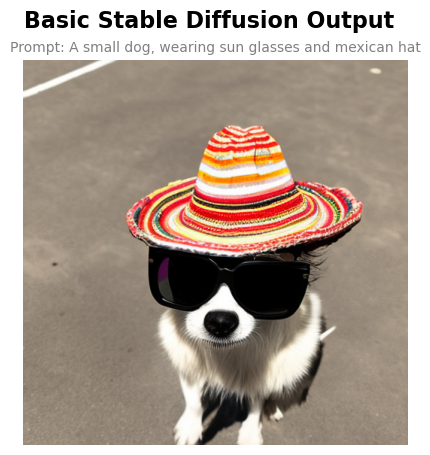

In [4]:
# show image generated
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

img = mpimg.imread("basic_stable_deffusion_check.png")

plt.figure(figsize=(5, 5)) 

plt.imshow(img) 
plt.axis("off") 

plt.suptitle("Basic Stable Diffusion Output", fontsize=16, fontweight='bold')
plt.title("Prompt: A small dog, wearing sun glasses and mexican hat", fontsize=10, color='gray')

plt.show() 

# 🔵2) implementing the base denoising loop from scratch

In [12]:
import torch
import PIL
import numpy as np
from tqdm.auto import tqdm

def get_text_embeddings(pipe, prompt, negative_prompt, device):
    """
    Encodes the prompt and negative prompt into text embeddings.
    """
    text_input = pipe.tokenizer(
        prompt, 
        padding="max_length", 
        max_length=pipe.tokenizer.model_max_length, 
        truncation=True, 
        return_tensors="pt"
    )
    text_embeddings = pipe.text_encoder(text_input.input_ids.to(device))[0]

    uncond_input = pipe.tokenizer(
        negative_prompt,  
        padding="max_length", 
        max_length=pipe.tokenizer.model_max_length, 
        truncation=True, 
        return_tensors="pt"
    )
    uncond_embeddings = pipe.text_encoder(uncond_input.input_ids.to(device))[0]

    text_embeddings = torch.cat([uncond_embeddings, text_embeddings])
    return text_embeddings


In [ ]:
def basic_text_to_image_stable(pipe, prompt, negative_prompt="", seed=None, steps=50, guidance_scale=7.5, height=512, width=512):
    """
    Custom bare-bones loop for Text-to-Image generation.
    """
    device = pipe.device
    
    if seed is not None:
        generator = torch.Generator(device=device).manual_seed(seed)
    else:
        generator = torch.Generator(device=device)

    # 1. Embed text
    text_embeddings = get_text_embeddings(pipe, prompt, negative_prompt, device)

    # 2. Initialize pure noise in the latent space
    pipe.scheduler.set_timesteps(steps)
    latents = torch.randn(
        (1, 4, height // 8, width // 8), 
        generator=generator, 
        device=device, 
        dtype=torch.float16
    )
    # Scale the initial noise by the scheduler's required standard deviation
    latents = latents * pipe.scheduler.init_noise_sigma
    
    # 3. Main Denoising Loop
    print("Running Denoising Loop...")
    for i, t in enumerate(tqdm(pipe.scheduler.timesteps)):
        
        # We duplicate the latents (x2) to run two parallel predictions in one batch 
        # (unconditional and conditional) for Classifier-Free Guidance.
        latent_model_input = torch.cat([latents] * 2)
        latent_model_input = pipe.scheduler.scale_model_input(latent_model_input, t)

        # Get the UNet prediction for the noise
        with torch.no_grad():
            noise_pred = pipe.unet(latent_model_input, t, encoder_hidden_states=text_embeddings).sample

        # Split the prediction back into unconditional and conditional
        noise_pred_uncond, noise_pred_text = noise_pred.chunk(2)

        # Apply the Guidance formula
        noise_pred = noise_pred_uncond + guidance_scale * (noise_pred_text - noise_pred_uncond)

        # Subtract the predicted noise from the latents
        latents = pipe.scheduler.step(noise_pred, t, latents).prev_sample
    
    # 4. Final decode from latent space to image space using the VAE
    with torch.no_grad():
        latents = 1 / 0.18215 * latents
        image = pipe.vae.decode(latents).sample

    # 5. Format to PIL Image
    image = (image / 2 + 0.5).clamp(0, 1)
    image = image.cpu().permute(0, 2, 3, 1).float().numpy()
    final_image = PIL.Image.fromarray((image[0] * 255).round().astype("uint8"))
    
    return final_image

# 🔵3) implementing the base denoising loop using PIXAR insted

### 🟠3.1) first step, tokenizing the prompt, and deleating the model from memory

In [1]:
%pip install sentencepiece protobuf

Note: you may need to restart the kernel to use updated packages.


In [9]:
import torch
import PIL
import numpy as np
import gc
from tqdm.auto import tqdm
from diffusers import PixArtAlphaPipeline, Transformer2DModel, AutoencoderKL
from transformers import T5EncoderModel
from IPython.display import display

# --- שלב 1: טעינה זמנית של ה-T5 לצורך קידוד הטקסט בלבד ---
print("Loading T5 Text Encoder temporarily...")
model_id = "PixArt-alpha/PixArt-XL-2-512x512"

# טוענים רק את מקודד השפה ישירות ל-GPU
text_encoder = T5EncoderModel.from_pretrained(
    model_id, 
    subfolder="text_encoder", 
    torch_dtype=torch.float16
).to("cuda")

# טוענים את ה-Tokenizer שלו
from transformers import T5Tokenizer
tokenizer = T5Tokenizer.from_pretrained(model_id, subfolder="tokenizer")

#prompt = "A small dog, suppressing a smile, wearing sun glasses and mexican hat"
prompt = "a small dog with a mexican hat"
negative_prompt = ""

# תהליך קידוד ידני של הפרומפט בעזרת ה-T5
device = torch.device("cuda")
max_sequence_length = 120 # הערך הסטנדרטי של PixArt

def encode_text(prompt, negative_prompt):
    # קידוד חיובי
    text_inputs = tokenizer(
        prompt,
        padding="max_length",
        max_length=max_sequence_length,
        truncation=True,
        return_tensors="pt",
    )
    text_input_ids = text_inputs.input_ids.to(device)
    prompt_attention_mask = text_inputs.attention_mask.to(device)
    prompt_embeds = text_encoder(text_input_ids, attention_mask=prompt_attention_mask)[0]

    # קידוד שלילי (Classifier-Free Guidance)
    uncond_inputs = tokenizer(
        negative_prompt,
        padding="max_length",
        max_length=max_sequence_length,
        truncation=True,
        return_tensors="pt",
    )
    uncond_input_ids = uncond_inputs.input_ids.to(device)
    negative_attention_mask = uncond_inputs.attention_mask.to(device)
    negative_prompt_embeds = text_encoder(uncond_input_ids, attention_mask=negative_attention_mask)[0]

    return prompt_embeds, prompt_attention_mask, negative_prompt_embeds, negative_attention_mask

print("Encoding prompt...")
with torch.no_grad():
    p_embeds, p_mask, n_embeds, n_mask = encode_text(prompt, negative_prompt)

# שילוב לטובת ה-CFG (שלילי למעלה, חיובי למטה)
prompt_embeds = torch.cat([n_embeds, p_embeds], dim=0)
prompt_attention_mask = torch.cat([n_mask, p_mask], dim=0)

# --- מחיקה מוחלטת של ה-T5 מהזיכרון! ---
print("Unloading T5 from VRAM...")
del text_encoder
del tokenizer
torch.cuda.empty_cache()
gc.collect()
print(f"VRAM after clearing T5: {torch.cuda.memory_allocated() / 1024**3:.2f} GB")

Loading T5 Text Encoder temporarily...


Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

Encoding prompt...
Unloading T5 from VRAM...
VRAM after clearing T5: 1.33 GB


### 🟠3.2) loading the model, and running it on the pre-made embeddings

Loading Transformer and VAE to GPU...


Some weights of the model checkpoint at PixArt-alpha/PixArt-XL-2-512x512 were not used when initializing PixArtTransformer2DModel: 
 ['caption_projection.y_embedding']


Running Denoising Loop on GPU...


  0%|          | 0/20 [00:00<?, ?it/s]

Decoding latents to image...


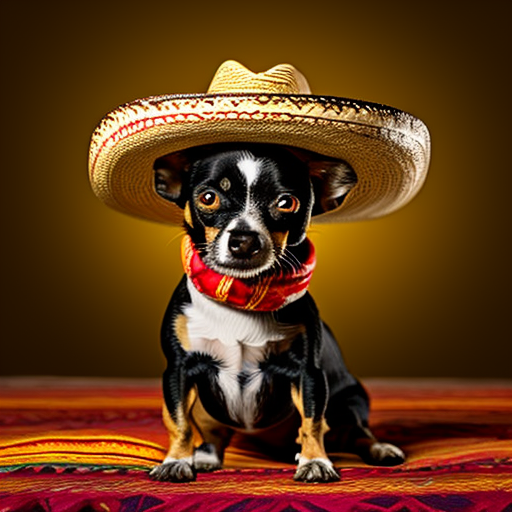

In [10]:

print("Loading Transformer and VAE to GPU...")
transformer = Transformer2DModel.from_pretrained(
    model_id, 
    subfolder="transformer", 
    torch_dtype=torch.float16
).to("cuda")

vae = AutoencoderKL.from_pretrained(
    model_id, 
    subfolder="vae", 
    torch_dtype=torch.float16
).to("cuda")

# טעינת Scheduler סטנדרטי
from diffusers import DPMSolverMultistepScheduler
scheduler = DPMSolverMultistepScheduler.from_pretrained(model_id, subfolder="scheduler")


# --- שלב 3: לולאת הדיפוזיה הידנית שלנו ---
def run_diffusion_loop(transformer, vae, scheduler, prompt_embeds, prompt_attention_mask, seed=42, steps=20, guidance_scale=4.5, height=512, width=512):
    generator = torch.Generator(device=device).manual_seed(seed)
    
    scheduler.set_timesteps(steps)
    latents = torch.randn(
        (1, 4, height // 8, width // 8), 
        generator=generator, 
        device=device, 
        dtype=torch.float16
    )
    latents = latents * scheduler.init_noise_sigma

    resolution = torch.tensor([height, width], dtype=torch.float16, device=device).repeat(2, 1)
    aspect_ratio = torch.tensor([float(height / width)], dtype=torch.float16, device=device).repeat(2, 1)
    added_cond_kwargs = {"resolution": resolution, "aspect_ratio": aspect_ratio}

    print("Running Denoising Loop on GPU...")
    for i, t in enumerate(tqdm(scheduler.timesteps)):
        latent_model_input = torch.cat([latents] * 2)
        
        t = t.to(device)
        latent_model_input = scheduler.scale_model_input(latent_model_input, t)

        t_val = t.item() if isinstance(t, torch.Tensor) else t
        t_batch = torch.tensor([t_val, t_val], device=device)

        with torch.no_grad():
            noise_pred = transformer(
                latent_model_input,
                encoder_hidden_states=prompt_embeds,
                encoder_attention_mask=prompt_attention_mask,
                timestep=t_batch,
                added_cond_kwargs=added_cond_kwargs,
                return_dict=False,
            )[0]

        if noise_pred.shape[1] == 8:
            noise_pred, _ = noise_pred.chunk(2, dim=1)

        noise_pred_uncond, noise_pred_text = noise_pred.chunk(2)
        noise_pred = noise_pred_uncond + guidance_scale * (noise_pred_text - noise_pred_uncond)

        latents = scheduler.step(noise_pred, t, latents).prev_sample
        latents = latents.to(device)

    # פיענוח סופי דרך ה-VAE
    print("Decoding latents to image...")
    with torch.no_grad():
        latents = (1 / vae.config.scaling_factor) * latents
        image = vae.decode(latents.to(vae.dtype)).sample

    image = (image / 2 + 0.5).clamp(0, 1)
    image = image.cpu().permute(0, 2, 3, 1).float().numpy()
    final_image = PIL.Image.fromarray((image[0] * 255).round().astype("uint8"))
    
    return final_image

# הרצה!
image = run_diffusion_loop(transformer, vae, scheduler, prompt_embeds, prompt_attention_mask, seed=42, steps=20, guidance_scale=7.5)
display(image)

# 🔵4) naive foveated diffusion (training-free mixed-resolution baseline)
The paper's *Naïve Mixed-Resolution Denoising* baseline: the pretrained PixArt denoises a mixed-resolution token sequence, with no training.
- inside the foveation mask: normal high-res tokens (each covers 16x16 pixels)
- outside it: one low-res token per 2x2 block of high-res tokens (covers 32x32 pixels), so 4x fewer tokens in the periphery
- the transformer blocks accept any token sequence; only the patch embedding, the positional embeddings and the unpatchify assume a grid, so we redo those per token. Low-res tokens get PixArt's sin-cos position at the centre of the block they replace (our stand-in for the paper's mixed-resolution RoPE)
- at the end the two parts are decoded separately by the VAE, the periphery is upsampled and the two are blended (Eq. 5-7)

Expected result: scale mismatches / duplicated objects around the fovea boundary (paper Fig. 4-5). Foveated training is what fixes this later.

Uses `transformer`, `vae`, `scheduler`, `prompt_embeds`, `prompt_attention_mask`, `device` and `run_diffusion_loop` from section 3 - run 3.1 and 3.2 first.

### 🟠4.1) foveated tokenization: masks, packing and positions

In [11]:
import time
import torch.nn.functional as F
import matplotlib.pyplot as plt
from diffusers.models.embeddings import get_2d_sincos_pos_embed_from_grid

P = transformer.config.patch_size      # 2 -> one token = 2x2 latent pixels = 16x16 image pixels
C = transformer.config.in_channels     # 4 latent channels
D = transformer.inner_dim              # 1152 hidden size
pe = transformer.pos_embed
POS_SCALE = pe.base_size / pe.height / pe.interpolation_scale   # PixArt's position scaling (=1 for the 512 model)
GRID = pe.height                       # the high-res token grid is GRID x GRID (32x32 for 512x512 images)

def patchify(z):
    """(B, C, H, W) latent grid -> (B, H/P * W/P, P*P*C) tokens, row-major, same layout PixArt uses to unpatchify."""
    B, c, H, W = z.shape
    return z.reshape(B, c, H // P, P, W // P, P).permute(0, 2, 4, 3, 5, 1).reshape(B, (H // P) * (W // P), P * P * c)

def unpatchify(tokens, h, w, c=C):
    """(B, h*w, P*P*c) tokens -> (B, c, h*P, w*P) latent grid."""
    B = tokens.shape[0]
    return tokens.reshape(B, h, w, P, P, c).permute(0, 5, 1, 3, 2, 4).reshape(B, c, h * P, w * P)

def make_circular_mask(center=(0.5, 0.5), radius=0.25, grid=GRID):
    """Circular foveation mask on the high-res token grid. center=(y, x) and radius are fractions of the image size."""
    ys, xs = torch.meshgrid(torch.arange(grid), torch.arange(grid), indexing="ij")
    ys, xs = (ys + 0.5) / grid, (xs + 0.5) / grid
    return (ys - center[0]) ** 2 + (xs - center[1]) ** 2 < radius ** 2

def build_layout(M):
    """
    Foveated token layout from a boolean mask M on the high-res token grid (h x w).
    Inside the fovea we keep every high-res token; outside it, one low-res token replaces each 2x2 block.
    Sequence order: [high-res tokens (row-major) | low-res tokens (row-major)].
    """
    h, w = M.shape
    Mb = M.reshape(h // 2, 2, w // 2, 2).any(dim=3).any(dim=1)     # block grid: True = block is in the fovea
    M = Mb.repeat_interleave(2, 0).repeat_interleave(2, 1)          # snap the mask to whole 2x2 blocks
    hi_idx = M.flatten().nonzero().squeeze(1)
    lo_idx = (~Mb).flatten().nonzero().squeeze(1)

    # token coordinates on the high-res token grid, in (x, y) order like PatchEmbed
    ys, xs = torch.meshgrid(torch.arange(h), torch.arange(w), indexing="ij")
    hi_xy = torch.stack([xs, ys], -1).reshape(-1, 2)[hi_idx].float()
    ys, xs = torch.meshgrid(torch.arange(h // 2), torch.arange(w // 2), indexing="ij")
    lo_xy = torch.stack([xs, ys], -1).reshape(-1, 2)[lo_idx].float() * 2 + 0.5   # centre of the 2x2 block it replaces
    xy = torch.cat([hi_xy, lo_xy]) * POS_SCALE

    # the same sin-cos embedding PixArt uses, just evaluated at our (possibly fractional) positions
    pos = get_2d_sincos_pos_embed_from_grid(D, xy.T.to(device), output_type="pt").float()[None]

    n_hi, n_lo = len(hi_idx), len(lo_idx)
    return dict(M=M, Mb=Mb, hi_idx=hi_idx.to(device), lo_idx=lo_idx.to(device), pos=pos,
                n_hi=n_hi, n_lo=n_lo, h=h, w=w, token_ratio=(n_hi + n_lo) / (h * w))

### 🟠4.2) PixArt forward pass on a foveated token sequence + sanity checks

In [12]:
@torch.no_grad()
def fov_transformer(x, t, layout, prompt_embeds, prompt_attention_mask):
    """
    PixArt forward pass on a packed foveated token sequence.
    x: (B, L, P*P*C) noisy latent patches -> returns the predicted noise, same shape.
    Same as transformer.forward(), except the steps that assume a regular grid
    (patch embedding, positions, unpatchify) are done per token.
    """
    B = x.shape[0]

    # 1. patch embedding: PixArt's conv (kernel = stride = P) is just a linear layer applied to each patch
    W_in = pe.proj.weight.permute(0, 2, 3, 1).reshape(D, P * P * C)   # (p, q, c) order, matches patchify()
    h = (F.linear(x, W_in, pe.proj.bias) + layout["pos"]).to(x.dtype)

    # 2. timestep + text conditioning, as in transformer.forward
    #    (resolution/aspect_ratio are ignored by the 512 model; the 1024 model needs real values here)
    t_emb, t_raw = transformer.adaln_single(t.expand(B), {"resolution": None, "aspect_ratio": None},
                                            batch_size=B, hidden_dtype=h.dtype)
    enc = transformer.caption_projection(prompt_embeds).view(B, -1, D)
    enc_bias = ((1 - prompt_attention_mask.to(h.dtype)) * -10000.0).unsqueeze(1)

    # 3. transformer blocks - these don't care about the grid, any token sequence works
    for block in transformer.transformer_blocks:
        h = block(h, attention_mask=None, encoder_hidden_states=enc, encoder_attention_mask=enc_bias,
                  timestep=t_emb, cross_attention_kwargs=None, class_labels=None)

    # 4. output head, per token
    shift, scale = (transformer.scale_shift_table[None] + t_raw[:, None]).chunk(2, dim=1)
    h = transformer.norm_out(h) * (1 + scale) + shift
    out = transformer.proj_out(h)                                          # (B, L, P*P*8)
    out = out.reshape(B, -1, P * P, transformer.out_channels)[..., :C]    # keep eps, drop the learned-variance channels
    return out.reshape(B, -1, P * P * C)

In [13]:
# sanity checks: with an all-high-res mask the foveated path must reproduce normal PixArt

# 1) positions: our embedding must equal PixArt's own table
full_layout = build_layout(torch.ones(GRID, GRID, dtype=torch.bool))
print("pos-embed max diff :", (full_layout["pos"] - pe.pos_embed).abs().max().item())    # expect ~0

# 2) forward pass: fov_transformer must match transformer(...)
scheduler.set_timesteps(20)
t = scheduler.timesteps[5].to(device)
z = torch.randn(2, C, GRID * P, GRID * P, device=device, dtype=torch.float16)
with torch.no_grad():
    ref = transformer(z, encoder_hidden_states=prompt_embeds, encoder_attention_mask=prompt_attention_mask,
                      timestep=t.expand(2), added_cond_kwargs={"resolution": None, "aspect_ratio": None},
                      return_dict=False)[0][:, :C]
out = unpatchify(fov_transformer(patchify(z), t, full_layout, prompt_embeds, prompt_attention_mask), GRID, GRID)
print("forward max diff   :", (ref - out).abs().max().item(), "| mean |eps|:", ref.abs().mean().item())  # expect small (fp16 noise, ~1e-2 or less)

pos-embed max diff : 0.0
forward max diff   : 0.0029296875 | mean |eps|: 0.79638671875


### 🟠4.3) foveated denoising loop and decoding
Same loop as 3.2, but the latent is a packed sequence of L patches instead of a 64x64 grid.

In [14]:
def to_pil(img):
    img = (img.float() / 2 + 0.5).clamp(0, 1)[0].permute(1, 2, 0).cpu().numpy()
    return PIL.Image.fromarray((img * 255).round().astype("uint8"))

def foveated_noise(layout, seed):
    """
    Initial noise for the packed sequence, taken from the SAME full-res noise run_diffusion_loop draws for this seed,
    so full-res and foveated runs are directly comparable. Low-res noise = 2x2 average * 2 (keeps unit variance).
    """
    g = torch.Generator(device=device).manual_seed(seed)
    z = torch.randn((1, C, layout["h"] * P, layout["w"] * P), generator=g, device=device, dtype=torch.float16)
    z_lo = (F.avg_pool2d(z.float(), 2) * 2).half()
    return torch.cat([patchify(z)[:, layout["hi_idx"]], patchify(z_lo)[:, layout["lo_idx"]]], dim=1)

def run_foveated_loop(layout, prompt_embeds, prompt_attention_mask, seed=42, steps=20, guidance_scale=4.5):
    scheduler.set_timesteps(steps)
    x = foveated_noise(layout, seed) * scheduler.init_noise_sigma      # (1, L, P*P*C) instead of (1, 4, 64, 64)
    for t in tqdm(scheduler.timesteps):
        t = t.to(device)
        x_in = scheduler.scale_model_input(torch.cat([x] * 2), t)
        eps_uncond, eps_text = fov_transformer(x_in, t, layout, prompt_embeds, prompt_attention_mask).chunk(2)
        eps = eps_uncond + guidance_scale * (eps_text - eps_uncond)
        x = scheduler.step(eps, t, x).prev_sample                     # scheduler math is elementwise, the shape doesn't matter
    return x

@torch.no_grad()
def decode_foveated(x, layout):
    """Split -> decode each part with the VAE -> upsample the periphery -> blend with the mask (paper Eq. 5-7)."""
    h, w, n_hi = layout["h"], layout["w"], layout["n_hi"]
    hi = torch.zeros(1, h * w, P * P * C, device=device, dtype=x.dtype)
    lo = torch.zeros(1, (h // 2) * (w // 2), P * P * C, device=device, dtype=x.dtype)
    hi[:, layout["hi_idx"]] = x[:, :n_hi]
    lo[:, layout["lo_idx"]] = x[:, n_hi:]
    z_hi, z_lo = unpatchify(hi, h, w), unpatchify(lo, h // 2, w // 2)          # (1,4,64,64) and (1,4,32,32)

    # fill each grid's empty part from the other one, so the VAE decoder doesn't see zeros next to the boundary
    m_hi = layout["M"].repeat_interleave(P, 0).repeat_interleave(P, 1).to(device)
    m_lo = layout["Mb"].repeat_interleave(P, 0).repeat_interleave(P, 1).to(device)
    z_lo = torch.where(m_lo, F.avg_pool2d(z_hi.float(), 2).to(z_hi.dtype), z_lo)
    z_hi = torch.where(m_hi, z_hi, F.interpolate(z_lo.float(), scale_factor=2, mode="nearest").to(z_hi.dtype))

    img_hi = vae.decode(z_hi / vae.config.scaling_factor).sample                  # (1,3,512,512)
    img_lo = vae.decode(z_lo / vae.config.scaling_factor).sample                  # (1,3,256,256)
    img_lo_up = F.interpolate(img_lo.float(), scale_factor=2, mode="bicubic")
    m_px = layout["M"].float().repeat_interleave(P * 8, 0).repeat_interleave(P * 8, 1).to(device)
    img = m_px * img_hi.float() + (1 - m_px) * img_lo_up
    return to_pil(img), to_pil(img_hi), to_pil(img_lo)

def draw_fovea_border(pil_img, layout, color=(255, 255, 255)):
    """White outline around the high-res region, like the figures in the paper."""
    m = F.interpolate(layout["M"].float()[None, None], size=pil_img.size[::-1], mode="nearest")
    ring = (F.max_pool2d(m, 5, stride=1, padding=2) - m)[0, 0] > 0
    arr = np.array(pil_img)
    arr[ring.numpy()] = color
    return PIL.Image.fromarray(arr)

### 🟠4.4) full high-res vs naive foveated (same prompt, same seed)
At 512x512 there are only 1024 tokens, so attention is not the bottleneck and the speedup is small; the point here is the image quality comparison.

tokens: 240 high-res + 196 low-res = 436 / 1024  (token ratio 43%)
Running Denoising Loop on GPU...


  0%|          | 0/30 [00:00<?, ?it/s]

Decoding latents to image...


  0%|          | 0/30 [00:00<?, ?it/s]

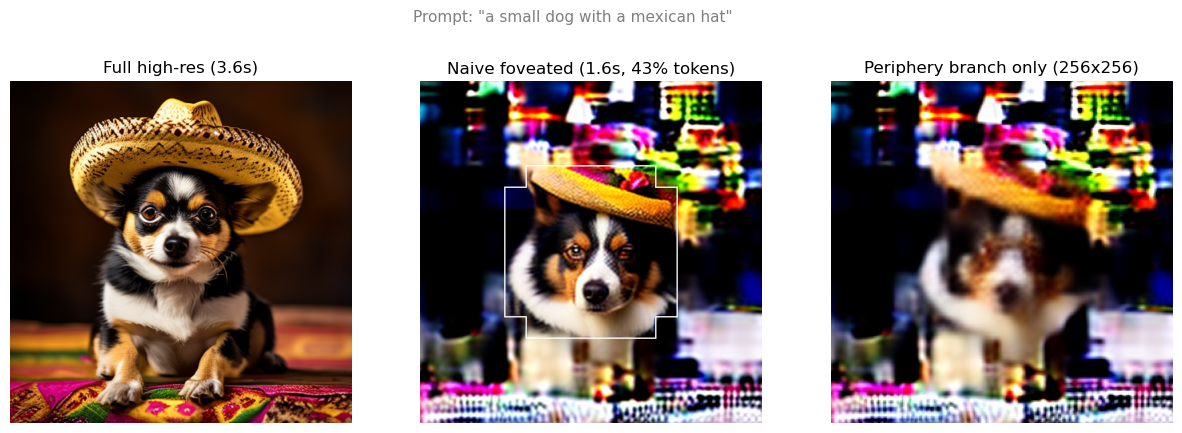

In [17]:
SEED, STEPS, GUIDANCE = 0, 30, 4.5

layout = build_layout(make_circular_mask(center=(0.5, 0.5), radius=0.25))
print(f"tokens: {layout['n_hi']} high-res + {layout['n_lo']} low-res = {layout['n_hi'] + layout['n_lo']} "
      f"/ {layout['h'] * layout['w']}  (token ratio {layout['token_ratio']:.0%})")

torch.cuda.synchronize(); t0 = time.time()
img_full = run_diffusion_loop(transformer, vae, scheduler, prompt_embeds, prompt_attention_mask,
                              seed=SEED, steps=STEPS, guidance_scale=GUIDANCE)
torch.cuda.synchronize(); t_full = time.time() - t0

t0 = time.time()
x = run_foveated_loop(layout, prompt_embeds, prompt_attention_mask, seed=SEED, steps=STEPS, guidance_scale=GUIDANCE)
img_fov, img_hi, img_lo = decode_foveated(x, layout)
torch.cuda.synchronize(); t_fov = time.time() - t0

panels = [
    (img_full, f"Full high-res ({t_full:.1f}s)"),
    (draw_fovea_border(img_fov, layout), f"Naive foveated ({t_fov:.1f}s, {layout['token_ratio']:.0%} tokens)"),
    (img_lo, "Periphery branch only (256x256)"),
]
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (im, title) in zip(axes, panels):
    ax.imshow(im)
    ax.set_title(title)
    ax.axis("off")
plt.suptitle(f'Prompt: "{prompt}"', fontsize=11, color="gray")
plt.show()

### 🟠4.5) different foveation patterns (same prompt and seed, like Fig. 9 in the paper)

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

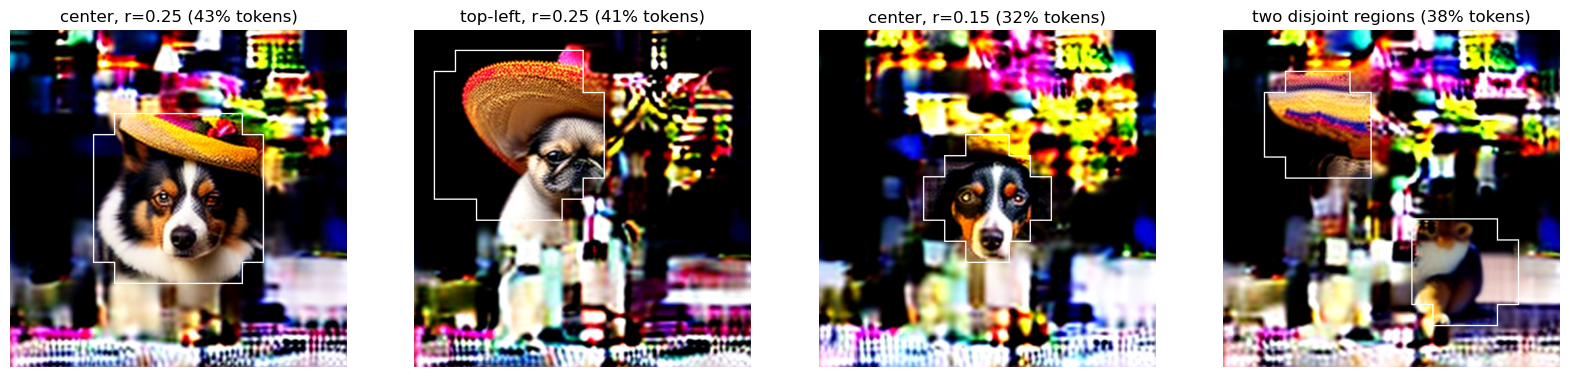

In [18]:
masks = {
    "center, r=0.25":       make_circular_mask((0.5, 0.5), 0.25),
    "top-left, r=0.25":     make_circular_mask((0.3, 0.3), 0.25),
    "center, r=0.15":       make_circular_mask((0.5, 0.5), 0.15),
    "two disjoint regions": make_circular_mask((0.3, 0.3), 0.15) | make_circular_mask((0.7, 0.7), 0.15),
}

fig, axes = plt.subplots(1, len(masks), figsize=(5 * len(masks), 5))
for ax, (name, M) in zip(axes, masks.items()):
    lay = build_layout(M)
    x = run_foveated_loop(lay, prompt_embeds, prompt_attention_mask, seed=SEED, steps=STEPS, guidance_scale=GUIDANCE)
    img_fov, _, _ = decode_foveated(x, lay)
    ax.imshow(draw_fovea_border(img_fov, lay))
    ax.set_title(f"{name} ({lay['token_ratio']:.0%} tokens)")
    ax.axis("off")
plt.show()